# Study Notebook (TF-IDF)

Since we must initialize the SDK with a embedding backend, this notebook uses the tf-idf embedder.

In [1]:
import sys
import re
from pathlib import Path
from pprint import pprint
from time import perf_counter
from unittest.mock import patch

def find_project_root(start: Path) -> Path:
    current = start.resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "tibetan_pipeline").exists() and (candidate / "requirements.txt").exists():
            return candidate
    raise RuntimeError("Could not find project root containing tibetan_pipeline/ and requirements.txt")

project_root = find_project_root(Path.cwd())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from tibetan_pipeline import TibetanResearchSDK

print(f"project_root={project_root}")

/home/thomas/CERES/A03/Pilotstudie/tibetan-intertext-lab/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


project_root=/home/thomas/CERES/A03/Pilotstudie/tibetan-intertext-lab


In [2]:
sdk = TibetanResearchSDK(
    engine="botok_ours",
    embedding_backend="tfidf",
    source_format="unicode",
    model_id="tfidf",
)

sdk

In [3]:
# Sanity checks
sdk._tfidf_embedder()

# Data Loading
## Introduction
We are loading all texts for the exploratory study from the texts/ folder.

In [4]:
from dataclasses import dataclass
from typing import List, Optional, Tuple
from tibetan_pipeline import SegmentationView, EmbeddingView

In [5]:
@dataclass
class TextData:
    name: str
    orig_text: str
    text_no_stopwords: str
    segments_no_stopwords: SegmentationView | None = None
    embeddings_no_stopwords: EmbeddingView | None = None
    segments: SegmentationView | None = None
    embeddings: EmbeddingView | None = None

    def __repr__(self):
            return (
                f"TextData("
                f"name={self.name!r}, "
                f"text_len={len(self.orig_text)}, "
                f"text_no_stopwords_len={len(self.text_no_stopwords)}, "
                f"orig_text={self.orig_text[:25]}..., "
                f"text_no_stopwords={self.text_no_stopwords[:25]}..., "
                f"segments={True if self.segments else False}, "
                f"embeddings={True if self.embeddings else False}, "
                f"segments_no_stopwords={True if self.segments_no_stopwords else False}, "
                f"embeddings_no_stopwords={True if self.embeddings_no_stopwords else False}"
                f")"
            )

## Preparing Texts
**Important**: It is crucial to leave chars such as ་ and ། and ༎ in the texts since otherwise the segmenter doesn't work anymore.

In [6]:
STOPWORDS = None
with open("stopwords_selected.txt", "r") as f:
    STOPWORDS = f.read()
    STOPWORDS = STOPWORDS.replace("\n", "|").strip()

def _remove_stopwords(text: str) -> str:
    text = re.sub(fr"{STOPWORDS}", "", text)
    text = re.sub("\n|\t|\r|\\ufeff", "", text) 
    # Removing page numbers etc. [p.213] [(l. 22)] (22)
    text = re.sub(r"\[.*?\]|\(.*?\)", " ", text)
    text = re.sub(r"\s+", "", text)
    return text.strip()

In [7]:
# Loading all texts from folder
folder = Path("texts/")
text_list: List[TextData] = list()
for t in folder.glob("*.txt"):
    text_list.append(TextData(name=t.name, orig_text=t.read_text(encoding="utf-8"), text_no_stopwords=_remove_stopwords(t.read_text(encoding="utf-8"))))

In [8]:
# Sanity checks
print(text_list[0])

TextData(name="L1-rig-pa'i-khu-byug_V9-p302-324.txt", text_len=23095, text_no_stopwords_len=21678, orig_text=﻿༄༅། །རྒྱ་གར་སྐད་དུ། སྭསྟ..., text_no_stopwords=།རྒྱ་གར་སྐད་དུ།སྭསྟི་ཤྲི་..., segments=False, embeddings=Falsesegments_no_stopwords=False, embeddings_no_stopwords=False)


In [9]:
# Storing clean texts
for t in text_list:
    with open(f"texts_no_stopwords/{t.name}.txt", "w") as f:
        f.write(t.text_no_stopwords)

### Creating Segments (sentences)

In [10]:
for t in text_list:
    print(f"Processing {t.name}...")
    print("Processing original text...")
    t.segments = sdk.segment_text(t.orig_text)
    print("Processing texts without stopwords...")
    t.segments_no_stopwords = sdk.segment_text(t.text_no_stopwords)
print("Finished.")

Processing L1-rig-pa'i-khu-byug_V9-p302-324.txt...
Processing original text...
Processing texts without stopwords...
Processing 05-SMDG-rig-pa-khu-byug-grel.txt...
Processing original text...
Processing texts without stopwords...
Processing V1b_rig-pa-khu-byug-vol4-267-271.txt...
Processing original text...
Processing texts without stopwords...
Processing V1a_khu-byug-vol5-306-308.txt...
Processing original text...
Processing texts without stopwords...
Processing 04-SMDG-rig-pa-khu-byug-gzhung.txt...
Processing original text...
Processing texts without stopwords...
Processing D1-rig-pa-khu-byug-comm_IOL-TJ647-karmay.txt...
Processing original text...
Processing texts without stopwords...
Finished.


In [11]:
# Sanity check
text_list[0]

TextData(name="L1-rig-pa'i-khu-byug_V9-p302-324.txt", text_len=23095, text_no_stopwords_len=21678, orig_text=﻿༄༅། །རྒྱ་གར་སྐད་དུ། སྭསྟ..., text_no_stopwords=།རྒྱ་གར་སྐད་དུ།སྭསྟི་ཤྲི་..., segments=True, embeddings=Falsesegments_no_stopwords=True, embeddings_no_stopwords=False)

In [12]:
text_list[0].segments_no_stopwords.to_dataframe()

,segment_index,start,end,segment_text
0,0,0,39,།རྒྱ་གར་སྐད་དུ།སྭསྟི་ཤྲི་བིདྱཱ་ཀོ་ཀི་ལ།
1,1,39,82,བོད་སྐད་དུ།བཀྲ་ཤིས་པའི་དཔལ་རིག་པའི་ཁུ་བྱུག།
2,2,82,127,བཅོམ་ལྡན་འདས་དཔལ་ཀུན་ཏུ་བཟང་པོ་ལ་ཕྱག་འཚལ་ལོ།།
3,3,127,163,འདི་སྐད་བདག་གིས་ཐོས་པའི་དུས་གཅིག་ན།།
4,4,163,219,དུས་གསུམ་གྱི་བཞིན་གཤེགས་པ་བཅོམ་ལྡན་འདས་ཐམས་ཅད་...
...,...,...,...,...
508,508,21419,21449,རུལ་མྱགས་ཚིག་ནས་དམྱལ་བར་འགྲོ།།
509,509,21449,21487,བཀྲ་ཤིས་པ་རིག་པའི་ཁུ་བྱུག་གི་རྒྱུད་ལས།
510,510,21487,21580,རྒྱུད་ཀྱི་རྒྱལ་པོ་ལ་བསྟོད་པ་དང་།རྒྱུད་གཏད་པ་དང...
511,511,21580,21608,བཀྲ་ཤིས་པའི་རྒྱུད་རྫོགས་སོ།།


### Creating Embeddings
Using tfidf, this part won't work anymore since we do not have a global dicionary. Instead, the embeddings will be created based when doing a doc x doc pairwise comparison. This might not be intended. To allow for global comparisons, we can also first create a vocabulary via tfidf.fit() based on the whole corpus. However, it is crucial that we only use sdk.embed_sentences() once we have intitilized our gloabel dictionary.

In [21]:
# We create customized sdk to tune tfidf params
sdk_tfidf =  sdk = TibetanResearchSDK(
    engine="botok_ours",
    embedding_backend="tfidf",
    source_format="unicode",
    model_id="tfidf-tuned",
    tfidf_max_features=500
)

In [22]:
embedder = sdk_tfidf._tfidf_embedder()

In [14]:
# Getting all docs and their segments (no stopwords)
doc_list = [t.segments_no_stopwords.segments for t in text_list]

In [ ]:
#text_list[0].segments_no_stopwords.segments

In [23]:
# Fit global tfidf vocabulary
tfidf_embeddings = embedder.encode_document_lists(doc_list)

In [24]:
tfidf_embeddings

[EmbeddingResult(model_id='tfidf:botok:ngram=1-1:min_df=1:max_df=1.0:max_features=500:sublinear_tf=False', embeddings=array([[0.       , 0.       , 0.       , ..., 0.       , 0.       ,
         0.       ],
        [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
         0.       ],
        [0.2640351, 0.       , 0.       , ..., 0.       , 0.       ,
         0.       ],
        ...,
        [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
         0.       ],
        [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
         0.       ],
        [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
         0.       ]], shape=(513, 500), dtype=float32)),
 EmbeddingResult(model_id='tfidf:botok:ngram=1-1:min_df=1:max_df=1.0:max_features=500:sublinear_tf=False', embeddings=array([[0.        , 0.        , 0.        , ..., 0.        , 0.        ,
         0.        ],
        [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
       

In [25]:
# Next, we add these embeddings to the TextData

In [26]:
for idx,t in enumerate(text_list):
    emb_res = tfidf_embeddings[idx] 
    t.embeddings_no_stopwords = EmbeddingView(
            model_id=emb_res.model_id,
            device="cpu",
            sentences=t.segments_no_stopwords.segments,
            embeddings=emb_res.embeddings,
        )
    

In [27]:
text_list

[TextData(name="L1-rig-pa'i-khu-byug_V9-p302-324.txt", text_len=23095, text_no_stopwords_len=21678, orig_text=﻿༄༅། །རྒྱ་གར་སྐད་དུ། སྭསྟ..., text_no_stopwords=།རྒྱ་གར་སྐད་དུ།སྭསྟི་ཤྲི་..., segments=True, embeddings=Falsesegments_no_stopwords=True, embeddings_no_stopwords=True),
 TextData(name='05-SMDG-rig-pa-khu-byug-grel.txt', text_len=76568, text_no_stopwords_len=72200, orig_text=﻿[71]རིག་པ་ཁུ་བྱུག་གི་འགྲ..., text_no_stopwords=རིག་པ་ཁུ་བྱུག་གི་འགྲེལ་བ་..., segments=True, embeddings=Falsesegments_no_stopwords=True, embeddings_no_stopwords=True),
 TextData(name='V1b_rig-pa-khu-byug-vol4-267-271.txt', text_len=3356, text_no_stopwords_len=3181, orig_text=﻿ [267.3]
 ༎བཅོམ་ལྡན་འདས་ད..., text_no_stopwords=༎བཅོམ་ལྡན་འདས་དཔལ་ཀུན་ཏུ་..., segments=True, embeddings=Falsesegments_no_stopwords=True, embeddings_no_stopwords=True),
 TextData(name='V1a_khu-byug-vol5-306-308.txt', text_len=401, text_no_stopwords_len=371, orig_text=﻿
 
 [306]རྒྱ་གར་སྐད་དུ། ས་..., text_no_stopwords=རྒྱ་གར་སྐད་དུ།ས་ན་ཏི་མ

In [29]:
text_list[3].embeddings_no_stopwords

EmbeddingView(model_id='tfidf:botok:ngram=1-1:min_df=1:max_df=1.0:max_features=500:sublinear_tf=False', device='cpu', sentences=['རྒྱ་གར་སྐད་དུ།ས་ན་ཏི་མ་ཧཱ་དར་པ།', 'བོད་སྐད་དུ།རྫོགས་པ་ཆེན་པོ།', 'ས་གཅིག་པ།སྭ་སྟི།དཔལ་གྱི་དཔལ།', 'བཅོམ་ལྡན་འདས་དཔལ་ཀུན་ཏུ་བཟང་པོ་སྐུ་གསུང་ཐུགས་རྡོ་རྗེ་བབ་ཆེན་པོ་ལྷུན་གྱི་རྫོགས་པ་ཕྱག་འཚལ་ལོ།', 'སྣ་ཚོགས་རང་བཞིན་མི་གཉིས་ཀྱང་།ཆ་ཤས་ཉིད་དུ་སྤྲོས་དང་བྲལ།', 'ཇི་བཞིན་བ་མི་རྟོག་ཀྱང།རྣམ་པར་སྣང་མཛད་ཀུན་ཏུ་བཟང་།', 'ཟིན་པས་བརྩོལ་པའི་ནད་སྤང་ཏེ།ལྷུན་གྱི་གནས་པས་བཞག་པ་ཡིན།།', 'བྱང་ཆུབ་སེམས་རིགས་པ་ཁུག་བྱུག་རྫོགས་སོ།'], embeddings=array([[0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.29143944, 0.        , 0.2681273 , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.     

# Exploratory Data Analysis

In [30]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [31]:
loaded_data = text_list

## Text Statistics (INCLUDING stop words)

/tmp/ipykernel_231731/382111408.py:16: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


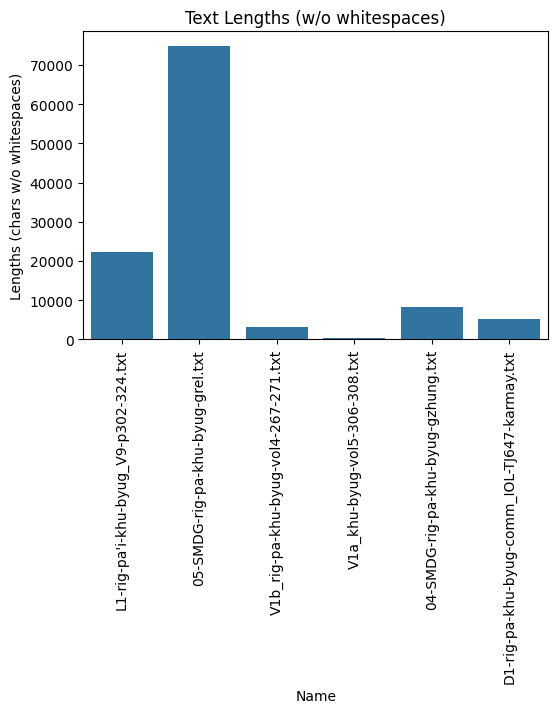

In [32]:
# Text lengths
import warnings
warnings.filterwarnings('ignore', category=UserWarning, message='Glyph.*missing from font')
df = pd.DataFrame({
    'Name': [t.name for t in loaded_data],
    'Length': [len(re.sub(f"\s+", "", t.orig_text)) for t in loaded_data]
})

# Barplot erstellen
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x='Name', y='Length')
plt.title('Text Lengths (w/o whitespaces)')
plt.xlabel('Name')
plt.ylabel('Lengths (chars w/o whitespaces)')
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig("images/text_len.png", dpi=300, bbox_inches='tight')

                                   Name  Length
0  L1-rig-pa'i-khu-byug_V9-p302-324.txt     516
1      05-SMDG-rig-pa-khu-byug-grel.txt    1241
2  V1b_rig-pa-khu-byug-vol4-267-271.txt      84
3         V1a_khu-byug-vol5-306-308.txt       8
4    04-SMDG-rig-pa-khu-byug-gzhung.txt     221


/tmp/ipykernel_231731/3163402529.py:17: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


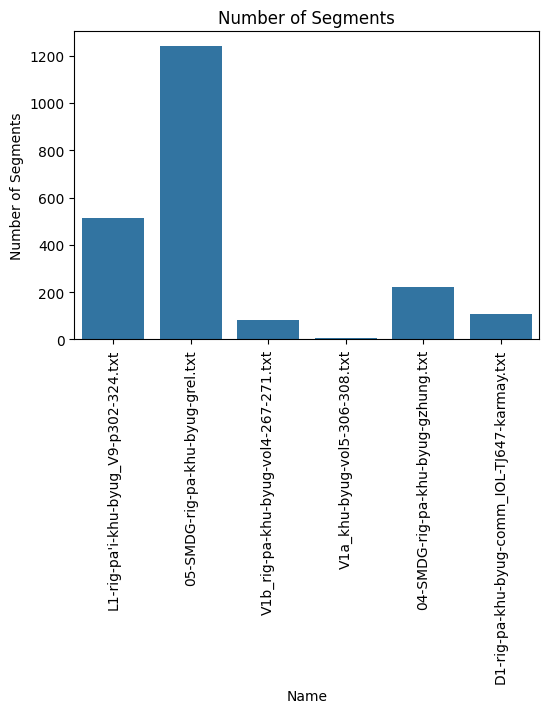

In [33]:
# Segment lengths
import warnings
warnings.filterwarnings('ignore', category=UserWarning, message='Glyph.*missing from font')
df = pd.DataFrame({
    'Name': [t.name for t in loaded_data],
    'Length': [len(t.segments.segments) for t in loaded_data]
})
print(df.head())

# Barplot erstellen
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x='Name', y='Length')
plt.title('Number of Segments')
plt.xlabel('Name')
plt.ylabel('Number of Segments')
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig("images/segment_number.png", dpi=300, bbox_inches='tight')

In [35]:
loaded_data[0].embeddings_no_stopwords.embeddings[0].size

500

In [36]:
len(loaded_data)

6

In [ ]:
#loaded_data[0].segments.segments

In [ ]:
#help(loaded_data[0].segments)

# Pairwise analysis of texts

In [38]:
# Creating a result set with pairwise views for each text combination
from itertools import combinations

results = []
for text_a, text_b in combinations(loaded_data, 2):
    result = sdk.pairwise_from_embedding_views(text_a.embeddings_no_stopwords, text_b.embeddings_no_stopwords)
    results.append((text_a.name, text_b.name, result))

In [39]:
# Makes sense because of n! / k! * (n-k)! -> 6! / 2! * 4! -> 6 * 5 / 2 -> 15
assert len(results) == 15

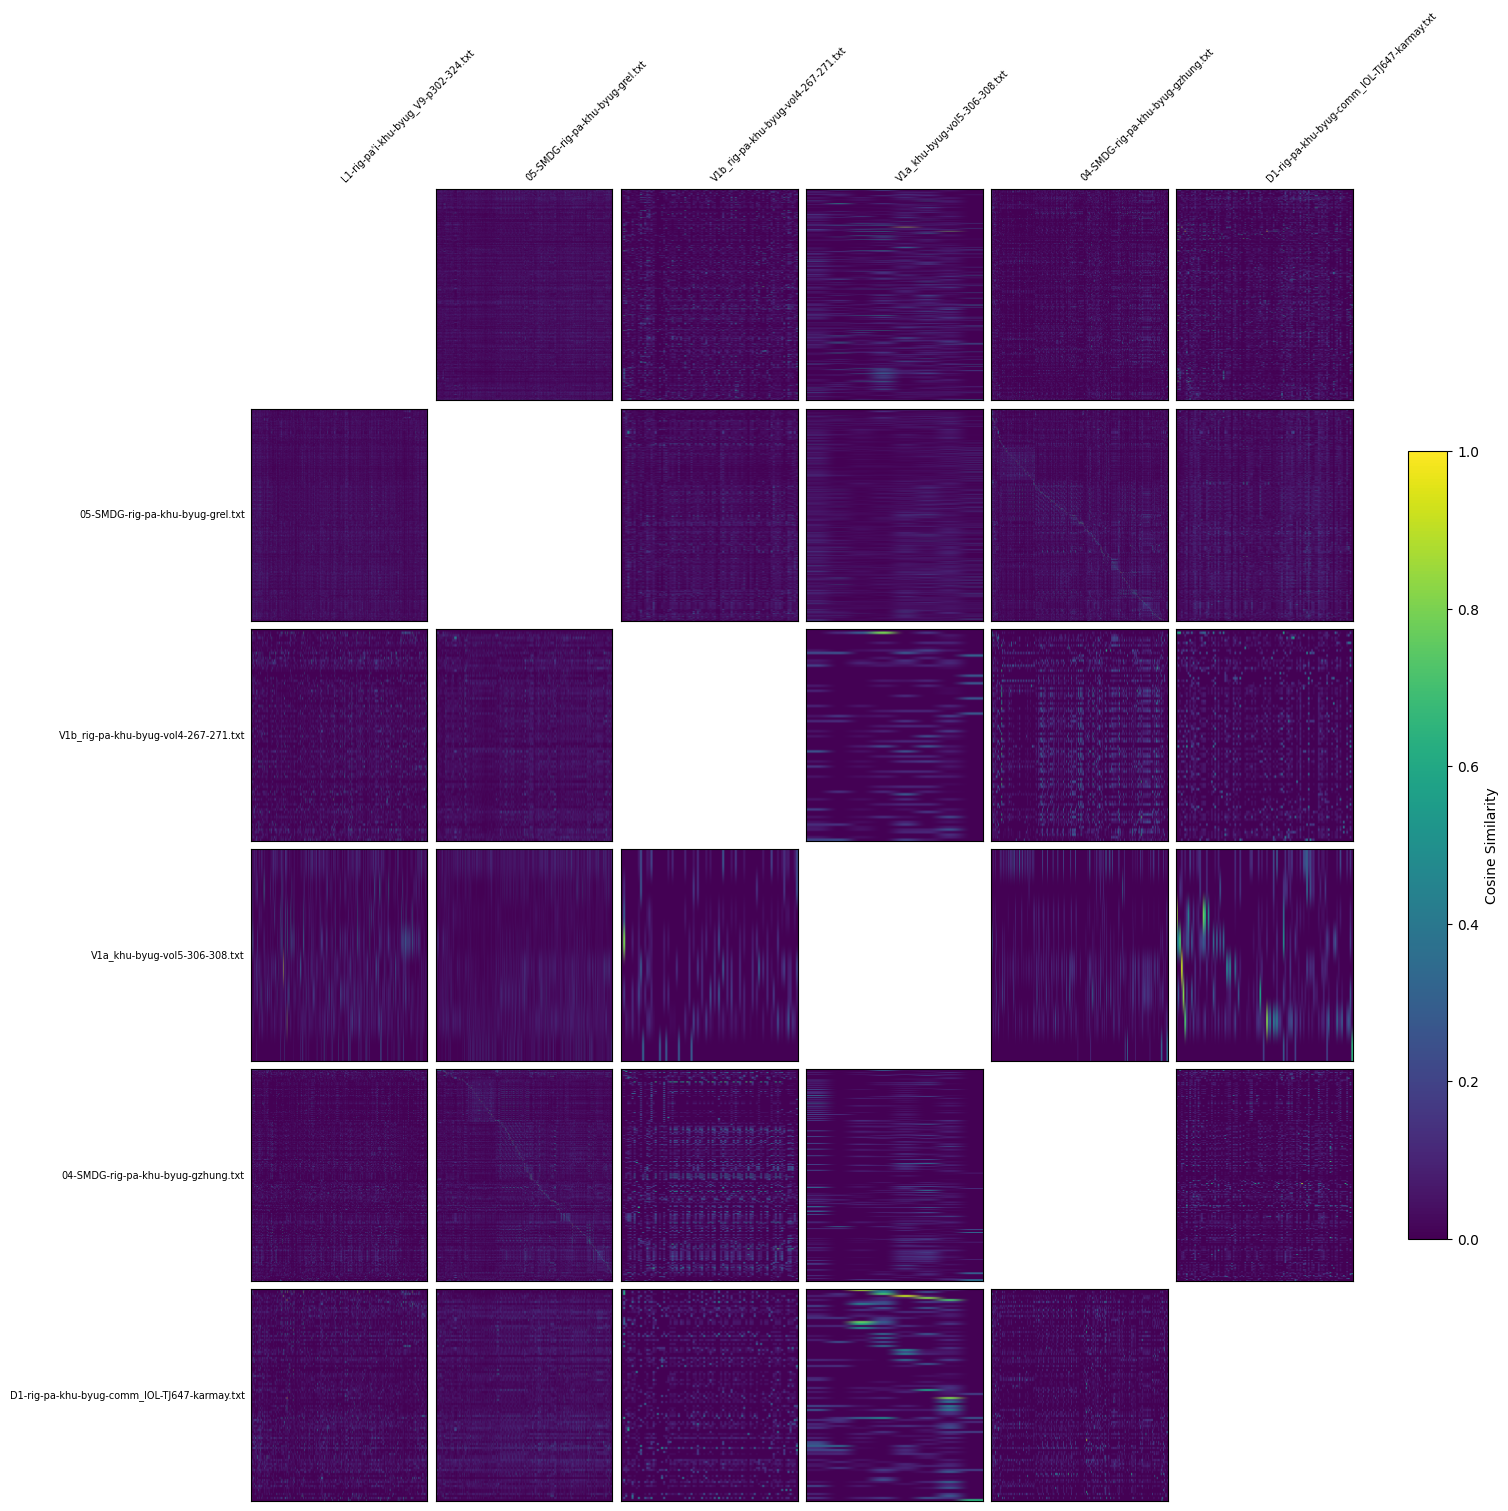

In [40]:
# We plot a matrix with all pairwise heatmaps
# IMPORTANT: Note that the heatmaps are stretched because the dimensionalities vary so greatly
# This does not really make sense...
from pathlib import Path
import matplotlib.pyplot as plt

PAIR_DIR = Path("images/pairs")
PAIR_DIR.mkdir(parents=True, exist_ok=True)

def save_single_heatmap(matrix, name_a, name_b, out_path, dpi=300):
    """Render one pairwise similarity matrix into its own figure and save it."""
    fig_single, ax_single = plt.subplots(figsize=(6, 5), constrained_layout=True)
    im_single = ax_single.imshow(matrix, cmap="viridis", vmin=0, vmax=1, aspect="equal")
    ax_single.set_xlabel(f"{Path(name_b).stem} (segments)", fontsize=8)
    ax_single.set_ylabel(f"{Path(name_a).stem} (segments)", fontsize=8)
    ax_single.set_title(f"{Path(name_a).stem} × {Path(name_b).stem}", fontsize=9)
    fig_single.colorbar(im_single, ax=ax_single, shrink=0.8, label="Cosine Similarity")
    fig_single.savefig(out_path, dpi=dpi, bbox_inches="tight")
    plt.close(fig_single)

text_names = [text.name for text in loaded_data]
n = len(text_names)
name_to_idx = {name: i for i, name in enumerate(text_names)}

fig, axes = plt.subplots(n, n, figsize=(2.5*n, 2.5*n), constrained_layout=True)

im = None
for text_a_name, text_b_name, pairwise_result in results:
    i, j = name_to_idx[text_a_name], name_to_idx[text_b_name]
    matrix = pairwise_result.similarity_matrix
    im = axes[i, j].imshow(matrix, cmap="viridis", vmin=0, vmax=1, aspect="auto")
    axes[j, i].imshow(matrix.T, cmap="viridis", vmin=0, vmax=1, aspect="auto")

    # Saving single heatmap individually
    slug_a, slug_b = Path(text_a_name).stem, Path(text_b_name).stem
    save_single_heatmap(
        matrix, text_a_name, text_b_name,
        PAIR_DIR / f"{i:02d}_{slug_a}__{j:02d}_{slug_b}.png",
    )

for i in range(n):
    axes[i, i].axis("off")

for i in range(n):
    for j in range(n):
        axes[i, j].set_xticks([])
        axes[i, j].set_yticks([])

for j in range(n):
    axes[0, j].set_title(text_names[j], fontsize=7, rotation=45, ha="left")

for i in range(n):
    axes[i, 0].set_ylabel(text_names[i], fontsize=7, rotation=0, ha="right", va="center")

fig.colorbar(im, ax=axes, shrink=0.6, label="Cosine Similarity")
plt.savefig("images/heatmap_plot.png", dpi=300, bbox_inches="tight")
plt.show()

Die Heatmaps sind ziemlicher Sondermüll. Schauen wir uns lieber die konkreten Stats der Embeddings vergleiche an.

Lass uns mal lieber anhand der Top Ähnlichkeiten schauen, wie ähnlich die Texte sind.

In [43]:
import pandas as pd
import numpy as np

text_names = [text.name for text in loaded_data]

df_max_scores = pd.DataFrame(
    np.nan, index=text_names, columns=text_names
)

# Diagonale über .loc setzen statt np.fill_diagonal
for name in text_names:
    df_max_scores.loc[name, name] = 1.0

# Werte eintragen (symmetrisch)
for text_a_name, text_b_name, pairwise_result in results:
    score = pairwise_result.metrics.max_score
    df_max_scores.loc[text_a_name, text_b_name] = score
    df_max_scores.loc[text_b_name, text_a_name] = score

df_max_scores

,L1-rig-pa'i-khu-byug_V9-p302-324.txt,05-SMDG-rig-pa-khu-byug-grel.txt,V1b_rig-pa-khu-byug-vol4-267-271.txt,V1a_khu-byug-vol5-306-308.txt,04-SMDG-rig-pa-khu-byug-gzhung.txt,D1-rig-pa-khu-byug-comm_IOL-TJ647-karmay.txt
L1-rig-pa'i-khu-byug_V9-p302-324.txt,1.000000,0.778292,0.926387,0.935212,0.694706,1.000000
05-SMDG-rig-pa-khu-byug-grel.txt,0.778292,1.000000,0.612577,0.511672,1.000000,0.800701
V1b_rig-pa-khu-byug-vol4-267-271.txt,0.926387,0.612577,1.000000,0.792867,0.735587,0.607592
V1a_khu-byug-vol5-306-308.txt,0.935212,0.511672,0.792867,1.000000,0.369637,0.906300
04-SMDG-rig-pa-khu-byug-gzhung.txt,0.694706,1.000000,0.735587,0.369637,1.000000,0.878883
D1-rig-pa-khu-byug-comm_IOL-TJ647-karmay.txt,1.000000,0.800701,0.607592,0.906300,0.878883,1.000000


Am aussagekräftigsten sind hier noch max_score und p95_score.

In [44]:
import pandas as pd
import numpy as np

text_names = [text.name for text in loaded_data]

df_mean_scores = pd.DataFrame(
    np.nan, index=text_names, columns=text_names
)

# Diagonale über .loc setzen statt np.fill_diagonal
for name in text_names:
    df_mean_scores.loc[name, name] = 1.0

# Werte eintragen (symmetrisch)
for text_a_name, text_b_name, pairwise_result in results:
    score = pairwise_result.metrics.p95_score
    df_mean_scores.loc[text_a_name, text_b_name] = score
    df_mean_scores.loc[text_b_name, text_a_name] = score

df_mean_scores

,L1-rig-pa'i-khu-byug_V9-p302-324.txt,05-SMDG-rig-pa-khu-byug-grel.txt,V1b_rig-pa-khu-byug-vol4-267-271.txt,V1a_khu-byug-vol5-306-308.txt,04-SMDG-rig-pa-khu-byug-gzhung.txt,D1-rig-pa-khu-byug-comm_IOL-TJ647-karmay.txt
L1-rig-pa'i-khu-byug_V9-p302-324.txt,1.000000,0.144848,0.160528,0.179367,0.132686,0.151565
05-SMDG-rig-pa-khu-byug-grel.txt,0.144848,1.000000,0.148835,0.144207,0.164023,0.155581
V1b_rig-pa-khu-byug-vol4-267-271.txt,0.160528,0.148835,1.000000,0.135077,0.194668,0.125205
V1a_khu-byug-vol5-306-308.txt,0.179367,0.144207,0.135077,1.000000,0.119867,0.239986
04-SMDG-rig-pa-khu-byug-gzhung.txt,0.132686,0.164023,0.194668,0.119867,1.000000,0.117577
D1-rig-pa-khu-byug-comm_IOL-TJ647-karmay.txt,0.151565,0.155581,0.125205,0.239986,0.117577,1.000000


In [45]:
import pandas as pd
import numpy as np

text_names = [text.name for text in loaded_data]

df_mean_scores = pd.DataFrame(
    np.nan, index=text_names, columns=text_names
)

# Diagonale über .loc setzen statt np.fill_diagonal
for name in text_names:
    df_mean_scores.loc[name, name] = 1.0

# Werte eintragen (symmetrisch)
for text_a_name, text_b_name, pairwise_result in results:
    score = pairwise_result.metrics.mean_above_p95
    df_mean_scores.loc[text_a_name, text_b_name] = score
    df_mean_scores.loc[text_b_name, text_a_name] = score

df_mean_scores

,L1-rig-pa'i-khu-byug_V9-p302-324.txt,05-SMDG-rig-pa-khu-byug-grel.txt,V1b_rig-pa-khu-byug-vol4-267-271.txt,V1a_khu-byug-vol5-306-308.txt,04-SMDG-rig-pa-khu-byug-gzhung.txt,D1-rig-pa-khu-byug-comm_IOL-TJ647-karmay.txt
L1-rig-pa'i-khu-byug_V9-p302-324.txt,1.000000,0.209433,0.238450,0.281313,0.200477,0.244322
05-SMDG-rig-pa-khu-byug-grel.txt,0.209433,1.000000,0.214981,0.197397,0.252377,0.219502
V1b_rig-pa-khu-byug-vol4-267-271.txt,0.238450,0.214981,1.000000,0.225665,0.278355,0.208058
V1a_khu-byug-vol5-306-308.txt,0.281313,0.197397,0.225665,1.000000,0.193070,0.417625
04-SMDG-rig-pa-khu-byug-gzhung.txt,0.200477,0.252377,0.278355,0.193070,1.000000,0.182798
D1-rig-pa-khu-byug-comm_IOL-TJ647-karmay.txt,0.244322,0.219502,0.208058,0.417625,0.182798,1.000000


In [46]:
import pandas as pd
import numpy as np

text_names = [text.name for text in loaded_data]

df_mean_scores = pd.DataFrame(
    np.nan, index=text_names, columns=text_names
)

# Diagonale über .loc setzen statt np.fill_diagonal
for name in text_names:
    df_mean_scores.loc[name, name] = 1.0

# Werte eintragen (symmetrisch)
for text_a_name, text_b_name, pairwise_result in results:
    score = pairwise_result.metrics.mean_best_a_to_b
    df_mean_scores.loc[text_a_name, text_b_name] = score
    df_mean_scores.loc[text_b_name, text_a_name] = score

df_mean_scores

,L1-rig-pa'i-khu-byug_V9-p302-324.txt,05-SMDG-rig-pa-khu-byug-grel.txt,V1b_rig-pa-khu-byug-vol4-267-271.txt,V1a_khu-byug-vol5-306-308.txt,04-SMDG-rig-pa-khu-byug-gzhung.txt,D1-rig-pa-khu-byug-comm_IOL-TJ647-karmay.txt
L1-rig-pa'i-khu-byug_V9-p302-324.txt,1.000000,0.403004,0.275150,0.148185,0.306178,0.317017
05-SMDG-rig-pa-khu-byug-grel.txt,0.403004,1.000000,0.228824,0.118721,0.400640,0.268886
V1b_rig-pa-khu-byug-vol4-267-271.txt,0.275150,0.228824,1.000000,0.103622,0.419026,0.263878
V1a_khu-byug-vol5-306-308.txt,0.148185,0.118721,0.103622,1.000000,0.281297,0.669929
04-SMDG-rig-pa-khu-byug-gzhung.txt,0.306178,0.400640,0.419026,0.281297,1.000000,0.229633
D1-rig-pa-khu-byug-comm_IOL-TJ647-karmay.txt,0.317017,0.268886,0.263878,0.669929,0.229633,1.000000


In [47]:
import pandas as pd
import numpy as np

text_names = [text.name for text in loaded_data]

df_mean_scores = pd.DataFrame(
    np.nan, index=text_names, columns=text_names
)

# Diagonale über .loc setzen statt np.fill_diagonal
for name in text_names:
    df_mean_scores.loc[name, name] = 1.0

# Werte eintragen (symmetrisch)
for text_a_name, text_b_name, pairwise_result in results:
    score = pairwise_result.metrics.mean_best_b_to_a
    df_mean_scores.loc[text_a_name, text_b_name] = score
    df_mean_scores.loc[text_b_name, text_a_name] = score

df_mean_scores

,L1-rig-pa'i-khu-byug_V9-p302-324.txt,05-SMDG-rig-pa-khu-byug-grel.txt,V1b_rig-pa-khu-byug-vol4-267-271.txt,V1a_khu-byug-vol5-306-308.txt,04-SMDG-rig-pa-khu-byug-gzhung.txt,D1-rig-pa-khu-byug-comm_IOL-TJ647-karmay.txt
L1-rig-pa'i-khu-byug_V9-p302-324.txt,1.000000,0.365624,0.403779,0.653846,0.377771,0.458869
05-SMDG-rig-pa-khu-byug-grel.txt,0.365624,1.000000,0.447534,0.375003,0.632878,0.416356
V1b_rig-pa-khu-byug-vol4-267-271.txt,0.403779,0.447534,1.000000,0.325993,0.245147,0.246605
V1a_khu-byug-vol5-306-308.txt,0.653846,0.375003,0.325993,1.000000,0.106582,0.218050
04-SMDG-rig-pa-khu-byug-gzhung.txt,0.377771,0.632878,0.245147,0.106582,1.000000,0.314384
D1-rig-pa-khu-byug-comm_IOL-TJ647-karmay.txt,0.458869,0.416356,0.246605,0.218050,0.314384,1.000000


## Explain Pairs
Thanks to tf-idf's transparency, we can look at the vectors of selected matches and see which terms contributed most to the score.

In [59]:
text_a = "V1a_khu-byug-vol5-306-308.txt"
text_b = "D1-rig-pa-khu-byug-comm_IOL-TJ647-karmay.txt"

for r in results:
    if r[0] == text_a and r[1] == text_b:
        matrix = r[2].similarity_matrix
        max_val = matrix.max()
        ys, xs = np.where(matrix == max_val)
        print(f"Max values: {list(zip(ys, xs))}")
        print(matrix[4][3])
        print(r[2].segments_a[4])
        print(r[2].segments_b[3])
        print("Explain")
        emb_a = sdk_tfidf._tfidf_embedder().encode([r[2].segments_a[4]]).embeddings
        emb_b = sdk_tfidf._tfidf_embedder().encode([r[2].segments_b[3]]).embeddings
        print(f"{sdk_tfidf._tfidf_embedder().explain_pair(emb_a, emb_b)}")
        
        

Max values: [(np.int64(4), np.int64(3))]
0.90630007
སྣ་ཚོགས་རང་བཞིན་མི་གཉིས་ཀྱང་།ཆ་ཤས་ཉིད་དུ་སྤྲོས་དང་བྲལ།
སྣ་ཚོགས་རང་བཞིན་མྱི་གཉིས་ཀྱང།་ཆ་ཤས་ཉིད་དུ་སྤྲོས་དང་བྲལ།་
Explain
[{'term': 'སྤྲོས', 'value_a': 0.4617443382740021, 'value_b': 0.4390842914581299, 'contribution': 0.20274468560584324}, {'term': 'བྲལ', 'value_a': 0.42774561047554016, 'value_b': 0.4067540168762207, 'contribution': 0.1739872452620972}, {'term': 'སྣཚོགས', 'value_a': 0.41320517659187317, 'value_b': 0.3929271399974823, 'contribution': 0.16235952827039934}, {'term': 'རངབཞིན', 'value_a': 0.2996307611465454, 'value_b': 0.2849264144897461, 'contribution': 0.08537271844431871}, {'term': 'གཉིས', 'value_a': 0.2954362630844116, 'value_b': 0.28093773126602173, 'contribution': 0.08299919348464613}, {'term': 'ཀྱང', 'value_a': 0.24980662763118744, 'value_b': 0.2375473827123642, 'contribution': 0.059340910577990735}, {'term': 'ཉིད', 'value_a': 0.24489042162895203, 'value_b': 0.23287244141101837, 'contribution': 0.05702823036290772}, 

## Analyse eines Textpaares
Im Folgenden werden wir uns den SegemtWise View eines Dokument x Dokument Vergleichs anschauen, also quasi die Details einer einzelnen Zelle. Hierzu werden wir uns das Textpaar `05-SMDG-rig-pa-khu-byug-grel` (1241 Segmente) und `V1b_rig-pa-khu-byug-vol4-267-271` (84 Segmente) näher anschauen. Die Auswahl wurde getroffen, weil hier der mean_best_b_to_a Wert mit 0.667 relativ hoch war. 

In [ ]:
filtered_list = [res for res in results if res[0] == '05-SMDG-rig-pa-khu-byug-grel.txt' and res[1] == 'V1b_rig-pa-khu-byug-vol4-267-271.txt']
text_a_name, text_b_name, pairwise_view = filtered_list[0]

In [ ]:
pd.DataFrame(pairwise_view.similarity_matrix)

In [ ]:
#help(pairwise_view)

In [ ]:
pd.DataFrame(pairwise_view.matches)

In [ ]:
# Wir speichern erst einmal die Top Matches ab
pd.DataFrame(pairwise_view.matches).to_csv("results/05_V1b.csv")

In [ ]:
# Speichern der besten Matches von Segmenten in Text B (V1b_rig-pa-khu-byug-vol4-267-271) mit Segmenten in Text A (5-SMDG-rig-pa-khu-byug-grel)

In [ ]:
best_matches = np.argmax(pairwise_view.similarity_matrix, axis=0)

In [ ]:
pairwise_view.similarity_matrix[800]

In [ ]:
matches_list = list()
for idx_b, idx_a in enumerate(best_matches):
    _dict = {
        "text_a": pairwise_view.segments_a[idx_a],
        "text_b": pairwise_view.segments_b[idx_b],
        "text_a_segment_number": idx_a,
        "text_b_segment_number": idx_b,
        "score": pairwise_view.similarity_matrix[idx_a][idx_b]
    }
    matches_list.append(_dict)

pd.set_option('display.max_colwidth', None)

df = pd.DataFrame(matches_list)

In [ ]:
df.to_csv(f"results/{text_b_name}_{text_a_name}_segmentwise-best-matches.csv")

In [ ]:
# Sanity check
assert pairwise_results.similarity_matrix.shape[0] == len(loaded_data[0].segments.segments)
assert pairwise_results.similarity_matrix.shape[1] == len(loaded_data[1].segments.segments)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def render_cosine_heatmap(
    matrix,
    row_labels=None,
    col_labels=None,
    title="Matrix Heatmap",
    cmap="viridis",
    figsize=None,
    cbar=True,
    savefig=True,
    filename="heatmap.png"
):
    A = np.asarray(matrix)
    assert A.ndim == 2, "matrix muss 2D sein (n x m)."

    n, m = A.shape

    # Bei großen Dimensionen keine Ticklabels anzeigen (lesbarer + schneller)
    show_row = row_labels is not None and n <= 50
    show_col = col_labels is not None and m <= 50

    if figsize is None:
        figsize = (min(12, m/10), min(10, n/10))

    plt.figure(figsize=figsize)
    ax = sns.heatmap(
        A,
        cmap=cmap,
        annot=False,  # keine Werte einblenden
        xticklabels=(col_labels if show_col else False),
        yticklabels=(row_labels if show_row else False),
        square=False,
        cbar=cbar
    )
    ax.set_title(title)
    ax.set_xlabel("Columns (m)")
    ax.set_ylabel("Rows (n)")
    plt.tight_layout()
    if savefig:
        plt.savefig(f"data/{filename}", dpi=300)
    plt.show()

In [ ]:
render_cosine_heatmap(pairwise_results.similarity_matrix, filename="heatmap_8b.png")

In [ ]:
#pairwise_results.matches

In [ ]:
pairwise_results.topk_dataframe().to_csv("data/topk_matches_04-SMDG_05-SMDG_8b.csv")

In [ ]:
with patch("tibetan_pipeline.sdk.resolve_segmenter", side_effect=AssertionError("pairwise() should not construct a new segmenter")):
    pairwise_view = sdk.pairwise(text_a, text_b, top_k=5, batch_size=2)

display(pairwise_view.topk_dataframe())
print({
    "pairwise_segments_a": len(pairwise_view.segments_a),
    "pairwise_segments_b": len(pairwise_view.segments_b),
    "similarity_shape": pairwise_view.similarity_matrix.shape,
    "cached_embedders": len(sdk._embedders),
})


In [ ]:
saraswati_praise_text = """
༄༅། །སྒྲ་དབྱངས་ལྷ་མོ་དབྱངས་ཅན་མ་ལ་བསྟོད་པ།
 
ཨོཾ་བདེ་ལེགས་སུ་གྱུར་ཅིག
 

ཆུ་འཛིན་དཀར་པོའི་གློག་ཕྲེང་དྲ་བ་ཅན། །
མཁའ་ཡི་མཛེས་བྱེད་འདྲ་བའི་ཡིད་འཕྲོག་མ། །
དྲི་ཟའི་ན་ཆུང་དབུས་ན་འཇོ་སྒེག་མཁན། །
རིང་ནས་བརྩེ་བའི་ལྷ་མོ་ད་ཚུར་བྱོན། །
 

པད་མའི་བཞིན་ལ་གཡོ་ལྡན་བུང་བའི་མིག །
མཐོན་མཐིང་རལ་པའི་རྩེ་ན་འོད་དཀར་ཅན། །
རོལ་སྒེག་གར་གྱིས་འགྱིང་བའི་དབྱངས་ཅན་མ། །
ད་དུང་བདག་ལ་ངག་གི་དངོས་གྲུབ་སྩོལ། །
 

རོལ་རྩེད་གར་གྱི་ཉམས་ལྡན་རི་དྭགས་མིག །
མིག་གིས་བལྟ་བས་མི་ངོམ་ཡིད་འཕྲོག་མ། །
མ་ལྟར་བརྩེ་བ་ཁྱེད་ཀྱིས་བདག་གི་ངག །
ངག་དབང་ལྷ་མོ་ཉིད་དང་མཚུངས་པར་མཛོད། །
 

སྟོན་ཟླ་རྒྱས་པའི་དཔལ་ལས་ལྷག་པར་མཛེས། །
ཚངས་དབྱངས་སྙན་པའི་གདངས་ཀྱང་ཟིལ་གྱིས་གནོན། །
ཟབ་ཡངས་རྒྱ་མཚོའི་འཇིང་ལྟར་དཔག་དཀའ་བ། །
དབྱངས་ཅན་ལྷ་མོའི་སྐུ་གསུང་ཐུགས་ལ་འདུད། །
"""

In [ ]:
foundation_of_all_good_qualities_text = """
༄༅། །ཡོན་ཏན་གཞིར་གྱུར་མ་བཞུགས་སོ། །
 

ཡོན་ཏན་ཀུན་གྱི་གཞིར་གྱུར་དྲིན་ཅན་རྗེ། །
ཚུལ་བཞིན་བསྟེན་པ་ལམ་གྱི་རྩ་བ་རུ། །
ལེགས་པར་མཐོང་ནས་འབད་པ་དུ་མ་ཡིས། །
གུས་པ་ཆེན་པོས་བསྟེན་པར་བྱིན་གྱིས་རློབས། །
 

ལན་ཅིག་རྙེད་པའི་དལ་བའི་རྟེན་བཟང་འདི། །
ཤིན་ཏུ་རྙེད་དཀའ་དོན་ཆེ་ཤེས་གྱུར་ནས། །
ཉིན་མཚན་ཀུན་ཏུ་སྙིང་པོ་ལེན་པའི་བློ། །
རྒྱུན་ཆད་མེད་པར་སྐྱེ་བར་བྱིན་གྱིས་རློབས། །
 

ལུས་སྲོག་གཡོ་བ་ཆུ་ཡི་ཆུ་བུར་བཞིན། །
མྱུར་དུ་འཇིག་པའི་འཆི་བ་དྲན་པ་དང༌། །
ཤི་བའི་རྗེས་སུ་ལུས་དང་གྲིབ་མ་བཞིན། །
དཀར་ནག་ལས་འབྲས་ཕྱི་བཞིན་འབྲང་བ་ལ། །
 

ངེས་པ་བརྟན་པོ་རྙེད་ནས་ཉེས་པའི་ཚོགས། །
ཕྲ་ཞིང་ཕྲ་བ་རྣམས་ཀྱང་སྤོང་བ་དང༌། །
དགེ་ཚོགས་མཐའ་དག་སྒྲུབ་པར་བྱེད་པ་ལ། །
རྟག་ཏུ་བག་དང་ལྡན་པར་བྱིན་གྱིས་རློབས། །
 

སྤྱད་པས་མི་ངོམས་སྡུག་བསྔལ་ཀུན་གྱི་སྒོ། །
ཡིད་བརྟན་མི་རུང་སྲིད་པའི་ཕུན་ཚོགས་ཀྱི། །
ཉེས་དམིགས་རིག་ནས་ཐར་བའི་བདེ་བ་ལ། །
དོན་གཉེར་ཆེན་པོ་སྐྱེ་བར་བྱིན་གྱིས་རློབས། །
 

རྣམ་དག་བསམ་པ་དེ་ཡིས་དྲངས་པ་ཡི། །
དྲན་དང་ཤེས་བཞིན་བག་ཡོད་ཆེན་པོ་ཡིས། །
བསྟན་པའི་རྩ་བ་སོ་སོར་ཐར་བ་ལ། །
སྒྲུབ་པ་སྙིང་པོར་བྱེད་པར་བྱིན་གྱིས་རློབས། །
 

རང་ཉིད་སྲིད་མཚོར་ལྷུང་བ་ཇི་བཞིན་དུ། །
མར་གྱུར་འགྲོ་བ་ཀུན་ཀྱང་དེ་འདྲ་བར། །
མཐོང་ནས་འགྲོ་བ་སྒྲོལ་བའི་ཁུར་འཁྱེར་བའི། །
བྱང་ཆུབ་སེམས་མཆོག་འབྱོངས་པར་བྱིན་གྱིས་རློབས། །
 

སེམས་ཙམ་བསྐྱེད་ཀྱང་ཚུལ་ཁྲིམས་རྣམ་གསུམ་ལ། །
གོམས་པ་མེད་ན་བྱང་ཆུབ་མི་འགྲུབ་པར། །
ལེགས་པར་མཐོང་ནས་རྒྱལ་སྲས་སྡོམ་པ་ལ། །
བརྩོན་པ་དྲག་པོས་སློབ་པར་བྱིན་གྱིས་རློབས། །
 

ལོག་པའི་ཡུལ་ལ་གཡེངས་པ་ཞི་བྱེད་ཅིང༌། །
ཡང་དག་དོན་ལ་ཚུལ་བཞིན་དཔྱོད་པ་ཡིས། །
ཞི་གནས་ལྷག་མཐོང་ཟུང་དུ་འབྲེལ་བའི་ལམ། །
མྱུར་དུ་རྒྱུད་ལ་སྐྱེ་བར་བྱིན་གྱིས་རློབས། །
 

ཐུན་མོང་ལམ་སྦྱང་སྣོད་དུ་གྱུར་པ་ན། །
ཐེག་པ་ཀུན་གྱི་མཆོག་གྱུར་རྡོ་རྗེ་ཐེག།
སྐལ་བཟང་སྐྱེ་བོའི་འཇུག་ངོགས་དམ་པ་དེར། །
བདེ་བླག་ཉིད་དུ་འཇུག་པར་བྱིན་གྱིས་རློབས། །
 

དེ་ཚེ་དངོས་གྲུབ་རྣམ་གཉིས་སྒྲུབ་པའི་གཞི། །
རྣམ་དག་དམ་ཚིག་སྡོམ་པར་གསུངས་པ་ལ། །
བཅོས་མ་མིན་པའི་ངེས་པ་རྙེད་གྱུར་ནས། །
སྲོག་དང་བསྡོས་ཏེ་སྲུང་བར་བྱིན་གྱིས་རློབས། །
 

དེ་ནས་རྒྱུད་སྡེ་སྙིང་པོ་རིམ་གཉིས་ཀྱི། །
གནད་རྣམས་ཇི་བཞིན་རྟོགས་ནས་བརྩོན་པ་ཡིས། །
ཐུན་བཞིའི་རྣལ་འབྱོར་སྤྱོད་ལས་མི་གཡེལ་བར། །
དམ་པའི་གསུང་བཞིན་སྒྲུབ་པར་བྱིན་གྱིས་རློབས། །
 

དེ་ལྟར་ལམ་བཟང་སྟོན་པའི་བཤེས་གཉེན་དང༌། །
ཚུལ་བཞིན་སྒྲུབ་པའི་གྲོགས་རྣམས་ཞབས་བརྟན་ཅིང༌། །
ཕྱི་དང་ནང་གི་བར་དུ་གཅོད་པའི་ཚོགས། །
ཉེ་བར་ཞི་བར་བྱིན་གྱིས་བརླབ་ཏུ་གསོལ། །
 

སྐྱེ་བ་ཀུན་ཏུ་ཡང་དག་བླ་མ་དང་། །
འབྲལ་མེད་ཆོས་ཀྱི་དཔལ་ལ་ལོངས་སྤྱོད་ཅིང་། །
ས་དང་ལམ་གྱི་ཡོན་ཏན་རབ་རྫོགས་ནས། །
རྡོ་རྗེ་འཆང་གི་གོ་འཕང་མྱུར་ཐོབ་ཤོག །
 

ཅེས་པ་འདི་ནི་རྗེ་ཙོང་ཁ་པ་བློ་བཟང་གྲགས་པས་མཛད་པའོ། །
"""

In [ ]:
detailed_pairwise_view = sdk.pairwise(saraswati_praise_text, foundation_of_all_good_qualities_text, top_k=10)
detailed_pairwise_view.topk_dataframe()


In [ ]:
import sys
import importlib

modules_to_reload = [
    "tibetan_pipeline.embeddings",
    "tibetan_pipeline.pairwise",
    "tibetan_pipeline.pipeline",
    "tibetan_pipeline.sdk",
    "tibetan_pipeline",
]

for name in modules_to_reload:
    if name in sys.modules:
        importlib.reload(sys.modules[name])

from tibetan_pipeline import TibetanResearchSDK

sdk_reloaded = TibetanResearchSDK(
      engine="botok_ours",
      model_id="buddhist-nlp/gemma-2-mitra-e",
      device="mps",
      batch_size=1,
)

In [ ]:

t2 = perf_counter()
detailed_pairwise_cached_view = sdk_reloaded.pairwise_from_embedding_views(
    embedding_view_a,
    embedding_view_b,
    top_k=10,
)
t3 = perf_counter()

print({
    "saraswati_segments": len(seg_a.segments),
    "foundation_segments": len(seg_b.segments),
    "embedding_seconds": round(t1 - t0, 3),
    "pairwise_from_embeddings_seconds": round(t3 - t2, 3),
    "similarity_shape": detailed_pairwise_cached_view.similarity_matrix.shape,
})

detailed_pairwise_cached_view.topk_dataframe()


In [ ]:
sdk_controlled = TibetanResearchSDK(
    engine="botok_ours",
    source_format="unicode",
    model_id="buddhist-nlp/gemma-2-mitra-e",
    device="cpu",
    batch_size=1,
    torch_dtype="float32",
)

controlled_embedder = sdk_controlled._get_embedder(
    model_id=sdk_controlled.model_id,
    batch_size=sdk_controlled.batch_size,
    device=sdk_controlled.device,
    embedding_progress=sdk_controlled.embedding_progress,
    torch_dtype=sdk_controlled.torch_dtype,
    device_map=sdk_controlled.device_map,
    load_in_8bit=sdk_controlled.load_in_8bit,
)

pprint({
    "torch_dtype": controlled_embedder.torch_dtype,
    "device_map": controlled_embedder.device_map,
    "load_in_8bit": controlled_embedder.load_in_8bit,
})
